In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyomo.environ as pyo
import seaborn as sns

from concordia.utils import add_totals, skipnone
from pandas_indexing import concat, isin, ismatch
from pyomo.opt.base.solvers import OptSolver

from aneris import Harmonizer

from utils import make_scenario_facets

c:\Users\gidden\Miniconda3\envs\concordia\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base_year = 2020

In [3]:
model = (
    pd.read_csv("data/harm_test_model.csv.gz", index_col=list(range(6)))
    .rename(columns=int)
    .droplevel(["model", "scenario"])
    .loc[isin(gas=["CO2", "CH4"])]
)
hist = (
    pd.read_csv("data/harm_test_hist.csv.gz", index_col=list(range(4)))
    .rename(columns=int)
    .pix.semijoin(model.index, how="right")
    .loc[isin(gas=["CO2", "CH4"])]
)

In [4]:
# Simplify the problem first

agg_sectors = {
    "AFOLU": [
        "Agricultural Waste Burning",
        "Forest Burning",
        "Grassland Burning",
        "Agriculture",
        "Peat Burning",
        "Deforestation and other LUC",
        "CDR Afforestation",
    ],
    "International Transport": ["International Shipping", "Aircraft"],
    "Energy and Industrial Processes": [
        "Energy Sector|Modelled",
        "Energy Sector|Non-Modelled",
        "Industrial Sector",
        "Solvents Production and Application",
        "Transportation Sector",
        "Residential Commercial Other",
    ],
    "Other (CDR and Waste)": [
        "CDR BECCS",
        "CDR DACCS",
        "CDR EW",
        "CDR Industry",
        "CDR OAE Uptake Ocean",
        "Waste",
    ],
}
model = model.pix.aggregate(sector=agg_sectors)
hist = hist.pix.aggregate(sector=agg_sectors)

In [5]:
global_only = ["International Transport", "AFOLU"]


def filter_global_only(df, global_sectors, add_regional_totals=True):
    global_ = df.loc[isin(region="World", sector=global_sectors)]
    regional = df.loc[~isin(region="World") & ~isin(sector=global_sectors)]
    if add_regional_totals:
        regional_agg = (
            regional.groupby(df.index.names.difference(["region"]))
            .sum()
            .pix.assign(region="World")
            if add_regional_totals
            else None
        )
        return concat(skipnone(global_, regional, regional_agg))
    else:
        return concat(skipnone(global_, regional))


model = filter_global_only(model, global_only)
hist = filter_global_only(hist, global_only)

# First stage:

Global gas-totals

In [9]:
def gas_totals(df):
    return (
        df.loc[isin(region="World")]
        .groupby(df.index.names.difference(["sector"]))
        .sum()
        .pix.assign(sector="Total")
    )


model_gas_totals = gas_totals(model)
hist_gas_totals = gas_totals(hist)

In [31]:
harmonizer = Harmonizer(
    model_gas_totals,
    hist_gas_totals,
    harm_idx=["region", "gas", "sector"],
)

In [32]:
harmonized_gas_totals = harmonizer.harmonize(year=base_year)
harmonized_gas_totals = harmonized_gas_totals.pix.assign(
    method=harmonizer.methods_used
    if isinstance(harmonizer.methods_used, pd.Series)
    else harmonizer.methods_used["method"]
)

INFO:root:Harmonizing with reduce_ratio_2080


In [33]:
harmonizer.methods_used

region  gas  unit       sector
World   CH4  Mt CH4/yr  Total     reduce_ratio_2080
        CO2  Mt CO2/yr  Total     reduce_ratio_2080
Name: method, dtype: object

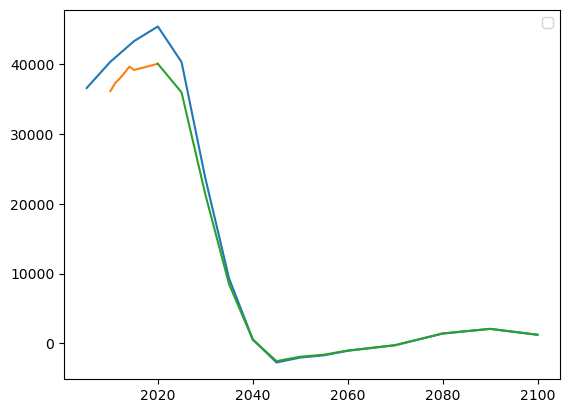

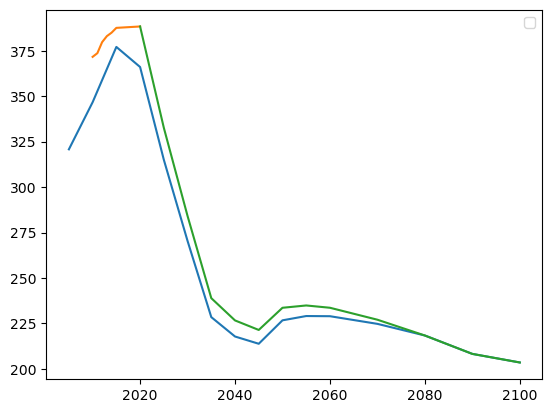

In [40]:
from matplotlib import pyplot as plt

for gas in ["CO2", "CH4"]:
    fig, ax = plt.subplots()
    model_gas_totals.loc[isin(gas=gas)].T.plot(label="model", ax=ax)  # blue
    hist_gas_totals.loc[isin(gas=gas)].T.plot(label="hist", ax=ax)  # yellow
    harmonized_gas_totals.loc[isin(gas=gas)].T.plot(label="harm", ax=ax)  # green
    ax.legend([])

# Main optimization function

In [44]:
solver = pyo.SolverFactory("ipopt")

In [ ]:
def distribute_level(
    model: pd.DataFrame,
    hist: pd.Series,
    harm_total: pd.Series,
    model_total: pd.Series,
    level: str,
    base_year: int,
    solver: str | OptSolver = "ipopt",
    options={},  # yes I know this is wrong
    converge=False,  # should be a double
    converge_year=False,
    opt_func="diff",
) -> pd.DataFrame:
    if isinstance(solver, str):
        solver = pyo.SolverFactory(solver)

    model = model.groupby(level).sum()
    hist = hist.groupby(level).sum()

    # indices
    years = model.columns
    components = model.index

    opt = pyo.ConcreteModel()
    opt.x = pyo.Var(years, components, initialize=0, domain=pyo.Reals)
    # Let's unpack those back into a dataframe for easy access
    x = (
        pd.Series(dict(opt.x.items()))
        .rename_axis(index=[years.name, level])
        .unstack(years.name)
    )

    def l2_norm_diff():
        delta_years = years.diff()[1:]
        delta_x = x.diff(axis=1).iloc[:, 1:]
        delta_m = model.diff(axis=1).iloc[:, 1:]
        return pyo.quicksum(
            np.ravel((delta_m / delta_years - delta_x / delta_years) ** 2)
        )

    def l2_norm_growth():
        delta_x = x.pct_change(axis=1).iloc[:, 1:]
        delta_m = model.pct_change(axis=1).iloc[:, 1:]
        return pyo.quicksum(np.ravel((delta_m - delta_x) ** 2))

    def l2_norm_growth_simple():
        return pyo.quicksum(
            (x.at[c, yf] * model.at[c, yi] - x.at[c, yi] * model.at[c, yf])
            ** 2  # / model.at[c, yi] ** 4
            for yf, yi in zip(years[1:], years[:-1])
            for c in components
        )

    if opt_func == "growth":
        opt.obj = pyo.Objective(expr=l2_norm_growth(), sense=pyo.minimize)
    elif opt_func == "growth_simple":
        opt.obj = pyo.Objective(expr=l2_norm_growth_simple(), sense=pyo.minimize)
    elif opt_func == "diff":
        opt.obj = pyo.Objective(expr=l2_norm_diff(), sense=pyo.minimize)

    opt.hist_val = pyo.Constraint(
        components, rule=lambda m, c: x.at[c, base_year] == hist.at[c]
    )
    opt.total_val = pyo.Constraint(
        years, rule=lambda m, y: pyo.quicksum(x[y]) == harm_total.at[y]
    )

    # harmonization can only progressively get better. TODO this is currently causing failures
    if converge is not False:  # be explicit to allow 0 values
        converge = 0.1 if converge is True else converge
        # yidx = range(1, len(years) - 1)
        # opt.converge = pyo.Constraint(
        #    components, yidx, rule=lambda m, c, yi: model.at[c, years[yi + 1]] - x.at[c, years[yi + 1]] <= (1 - converge) * (model.at[c, years[yi]] - x.at[c, years[yi]])
        # )
        # opt.converge_abs = pyo.Constraint(
        #    components, yidx, rule=lambda m, c, yi: np.abs(model.at[c, years[yi + 1]] - x.at[c, years[yi + 1]]) <= (1 - converge) * np.abs(model.at[c, years[yi]] - x.at[c, years[yi]])
        # )
        c_years = years[1:]
        opt.converge_total = pyo.Constraint(
            components,
            c_years,
            rule=lambda m, c, y: np.abs(model.at[c, y] - x.at[c, y])
            / np.abs(model.at[c, y])
            <= np.abs(model_total.at[y] - harm_total.at[y]) / np.abs(model_total.at[y]),
        )

    # the last year must be "close" (currently exactly equal)
    if converge_year:
        years = (
            [years[-1]]
            if converge_year is True
            else [y for y in years if y >= converge_year]
        )
        print(years)
        opt.converged_years = pyo.Constraint(
            components, years, rule=lambda m, c, y: x.at[c, y] == model.at[c, y]
        )
    results = solver.solve(opt, options=options)
    assert (results.solver.status == pyo.SolverStatus.ok) and (
        results.solver.termination_condition == pyo.TerminationCondition.optimal
    ), (
        f"ipopt terminated budget optimization with status: "
        f"{results.solver.status}, {results.solver.termination_condition}"
    )
    return x.map(pyo.value)

# Second-stage

Take global totals per gas species as input and harmonize regional totals such that they add up to this total.

In [86]:
model_sel = filter_global_only(
    model.loc[:, base_year:], global_only, add_regional_totals=False
)
hist_sel = filter_global_only(hist[base_year], global_only, add_regional_totals=False)

harmonized_region_totals = concat(
    distribute_level(
        model_sel.loc[isin(gas=gas)],
        hist_sel.loc[isin(gas=gas)],
        harmonized_gas_totals.loc[isin(gas=gas)].iloc[0],
        model_gas_totals.loc[isin(gas=gas)].iloc[0],
        level="region",
        base_year=base_year,
        solver=solver,
        converge=0.10,
        converge_year=2090,
        opt_func="diff",
        options=dict(max_iter=5000),
    ).pix.assign(gas=gas)
    for gas in model.pix.unique("gas")
)

[2090, 2100]


  - termination condition: maxIterations
  - message from solver: Ipopt 3.11.1\x3a Maximum Number of Iterations Exceeded.


AssertionError: ipopt terminated budget optimization with status: warning, maxIterations

In [57]:
make_scenario_facets(
    add_totals(harmonized_region_totals.pix.format(sector="Total", unit="Mt {gas}/yr"))
    .groupby(level=model.index.names)
    .sum(),
    add_totals(filter_global_only(hist, global_only, add_regional_totals=False)),
    add_totals(filter_global_only(model, global_only, add_regional_totals=False)),
    suffix="region-totals",
)

100%|██████████| 2/2 [00:05<00:00,  2.80s/it]


WindowsPath('results/harmonization-facetregion-totals.html')

In [68]:
concat(
    (
        add_totals(
            harmonized_region_totals.pix.format(sector="Total", unit="Mt {gas}/yr")
        )
        .groupby(level=model.index.names)
        .sum()
        .pix.assign(type="harmonized"),
        add_totals(
            filter_global_only(hist, global_only, add_regional_totals=False)
        ).pix.assign(type="hist"),
        add_totals(
            filter_global_only(model, global_only, add_regional_totals=False)
        ).pix.assign(type="model"),
    )
).sort_index(axis="columns").to_excel("./results/check-values-region-totals.xlsx")

# 3rd stage

In [90]:
harmonized = concat(
    distribute_level(
        model_sel.loc[isin(gas=gas, region=region)],
        hist_sel.loc[isin(gas=gas, region=region)],
        total=harmonized_region_totals.loc[isin(gas=gas, region=region)].iloc[0],
        level="sector",
        base_year=base_year,
        solver=solver,
        converge=False,
        last_year=True,
        opt_func="diff",
        options=dict(max_iter=5000, tol=1e-2),
    ).pix.assign(gas=gas, region=region, order=["gas", "region", "sector"])
    for gas, region in model.pix.unique(["gas", "region"])
).sort_index()

# Plotting

In [31]:
model_ = add_totals(filter_global_only(model, global_only, add_regional_totals=False))
hist_ = add_totals(filter_global_only(hist, global_only, add_regional_totals=False))
harmonized_ = add_totals(
    harmonized.pix.semijoin(model.index)
)  # hack the unit definitions back :)

<Axes: >

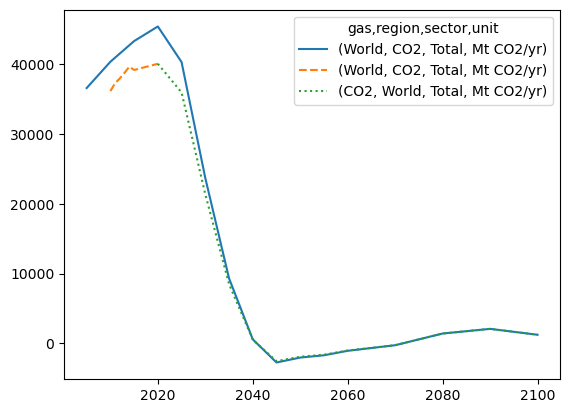

In [32]:
gas = "CO2"
ax = model_.loc[ismatch(gas=gas, region="World", sector="Total")].T.plot.line(
    linestyle="-"
)
hist_.loc[ismatch(gas=gas, region="World", sector="Total")].T.plot.line(
    linestyle="--", ax=ax
)
harmonized_.loc[ismatch(gas=gas, region="World", sector="Total")].T.plot.line(
    linestyle=":", ax=ax
)

In [33]:
make_scenario_facets(harmonized_, hist_, model_)

100%|██████████| 10/10 [00:13<00:00,  1.35s/it]


WindowsPath('results/harmonization-facet.html')

In [20]:
!open results/harmonization-facet.html

'open' is not recognized as an internal or external command,
operable program or batch file.
